# Data assimilation in the reservoir: an echo state network without a washout

An echo state network (ESN) forecasts from its input, $\boldsymbol{u}$, and its reservoir, $\boldsymbol{r}$, which must be synchronized with the system first. The standard washout drives the network with the full state for many consecutive steps. Here, an ensemble filter estimates $\boldsymbol{\psi} = [\boldsymbol{u}; \boldsymbol{r}]$ from sparse and noisy data instead. Test case: the Lorenz-63 system, with the network, data and filter of `scripts/esnda` (`configs/lorenz63.yml`). Tutorials 41-43 extend it to the Lorenz-96 system, partial observations and parameter estimation; the plotting helpers are in `aux_4X.py`.

In [1]:
import numpy as np

from romda.models.physical import Lorenz63
from romda.models.data_driven.rnns import model_esn
from romda.observations import Observations
from romda.estimators import EnSRKF
from romda.data_assimilation import as_result, deploy
from romda.metrics import state_metrics
from romda.run import innovation_options
from aux_4X import (BLUE, GREEN, VERMILLION, config, plot_errors, plot_members, plot_sweep, plot_washout,
                    valid_times, washout_forecasts)

CONFIG = config('lorenz63')
DA = CONFIG['da']

## 1. The network and its washout

`model_esn` trains the ESN (100 units) on 100 Lyapunov times of the record with 5 % noise, or loads it from the store. The held-out end of the record is the truth. Forecasts after a washout on noise-free and on noisy data:

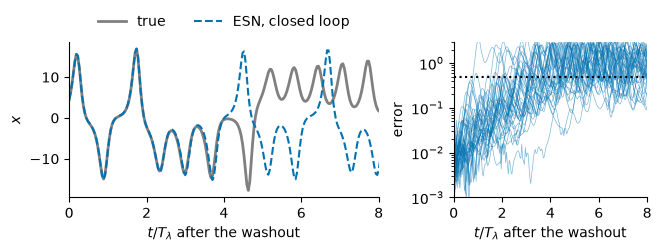

valid time after a washout on noise-free data: median 2.8 Lyapunov times


valid time after a washout on noisy data: median 1.7 Lyapunov times


In [2]:
esn, data = model_esn(Lorenz63, CONFIG['truth'], CONFIG['forecast']['esn'])
t_lyap, N_lyap, i_test = data['t_lyap'], data['N_lyap'], data['i_test']
clean, noisy = data['clean_data'][i_test:], data['noisy_data'][i_test:]
t = data['t'][i_test:] - data['t'][i_test]

n_forecast, starts = 300, np.arange(40) * 4 * N_lyap
t_forecast = np.arange(n_forecast) * esn.dt_ESN / t_lyap
forecast, target, errors = washout_forecasts(esn, clean, clean, starts, n_forecast)
plot_washout(t_forecast, target, forecast, errors)
for label, record in [('noise-free', clean), ('noisy', noisy)]:
    vt = valid_times(washout_forecasts(esn, record, clean, starts, n_forecast)[2], t_forecast)
    print(f'valid time after a washout on {label} data: median {np.median(vt):.1f} Lyapunov times')

The washout consumes 20 consecutive snapshots of the full state, and the forecast is valid for 2.8 Lyapunov times (1.7 when the washout data are noisy).

## 2. Deployment with the ensemble filter

The EnSRKF updates $[\boldsymbol{u}; \boldsymbol{r}]$ of 20 networks every 0.19 Lyapunov times. The observation operator selects rows of $\boldsymbol{\psi}$, so no Jacobian of the network is needed. Choices, from the configuration:

- the members start from reservoir states visited in training, i.e. on the attractor of the network;
- $\boldsymbol{\mathsf{C}}_{dd}$ has 0.2 of the standard deviation of each observable, four times the data noise, because it also covers the error of the network;
- the innovation-based inflation.

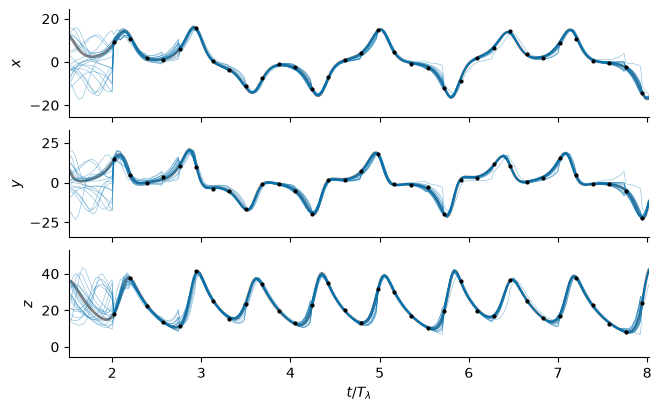

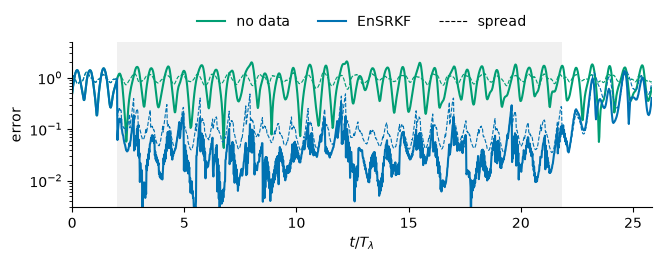

error 0.052, spread 0.116, valid time after the data 1.3 Lyapunov times


In [3]:
T_START, T_STOP, T_FORECAST = CONFIG['window_lyap']        # in Lyapunov times
FILTER = dict(m=DA['m'], da_method=DA['da_method'], cdd_fraction=DA['cdd_fraction'],
              inflation=DA['inflation'], **innovation_options(DA), t_extra=T_FORECAST * t_lyap)


def observe(Nt_obs=DA['Nt_obs'], window=0):
    """Noisy observations of x, y, z every `Nt_obs` steps; `window` moves the experiment by 4 Lyapunov times."""
    return Observations(y_raw=noisy, y_true=clean, t_true=t, Nt_obs=Nt_obs,
                        t_start=(T_START + 4 * window) * t_lyap, t_stop=(T_STOP + 4 * window) * t_lyap)


truth = observe()
run = deploy(esn, truth, measured=[0, 1, 2], **FILTER)
free = EnSRKF(parent_model=esn, m=DA['m'], measured=[0, 1, 2])
free.forecast_step(t_end=truth.t_obs[-1] + T_FORECAST * t_lyap, close=True)

plot_members(run, truth, t, clean, t_lyap)
plot_errors({'no data': (as_result(free), GREEN), 'EnSRKF': (run, BLUE)}, truth, t, clean, t_lyap)
s = state_metrics(run, truth, t, clean, t_lyap=t_lyap)
print(f"error {s['rmse_mean_sync']:.3f}, spread {s['spread_sync']:.3f}, "
      f"valid time after the data {s['valid_time_mean_forecast']:.1f} Lyapunov times")

The filter synchronizes the network at the first analyses, with no washout, and keeps the error at the level of the data noise. The ensemble is over-dispersed (spread about twice the error) because of the large $\boldsymbol{\mathsf{C}}_{dd}$, so the inflation does not act.

## 3. Filter or substitution?

With every component observed, the data can also replace the input of the network at each observation time (`bayesian_update=False`). This corrects $\boldsymbol{u}$ only; the filter also corrects $\boldsymbol{r}$. Medians over ten windows:

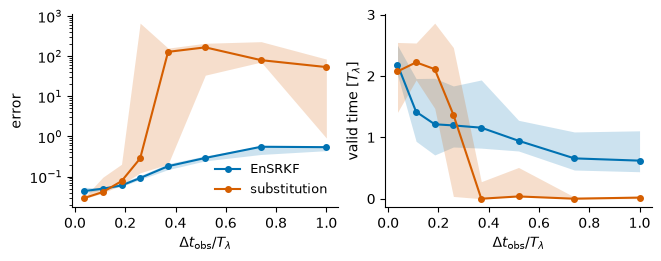

In [4]:
intervals = [2, 6, 10, 14, 20, 28, 40, 54]                 # Nt_obs, in steps of the record


def scores(run, truth):
    s = state_metrics(run, truth, t, clean, t_lyap=t_lyap)
    return s['rmse_mean_sync'], s['valid_time_mean_forecast']


sweep = np.zeros((2, len(intervals), 10, 2))
for i, Nt_obs in enumerate(intervals):
    for w in range(10):
        truth_w = observe(Nt_obs, window=w)
        sweep[0, i, w] = scores(deploy(esn, truth_w, measured=[0, 1, 2], **FILTER), truth_w)
        sweep[1, i, w] = scores(deploy(esn, truth_w, measured=[0, 1, 2], bayesian_update=False,
                                       open_loop_ensemble=True, m=DA['m'], t_extra=T_FORECAST * t_lyap), truth_w)
plot_sweep(np.array(intervals) * data['dt'] / t_lyap, {'EnSRKF': (sweep[0], BLUE), 'substitution': (sweep[1], VERMILLION)},
           r'$\Delta t_\mathrm{obs}/T_\lambda$', ['error', r'valid time [$T_\lambda$]'])

- Frequent data ($\Delta t_\mathrm{obs} \lesssim 0.2\,T_\lambda$): the substitution is as accurate as the filter. It is a washout spread over the data.
- Sparse data: the substitution fails from $0.37\,T_\lambda$, whereas the error of the filter stays bounded.

## 4. Estimating the readout

`est_alpha=['Wout']` appends the singular values of $\boldsymbol{\mathsf{W}}_\mathrm{out}$ to $\boldsymbol{\psi}$:

In [5]:
readout = np.zeros((2, 10, 2))
for w in range(10):
    truth_w = observe(window=w)
    readout[0, w] = scores(deploy(esn, truth_w, measured=[0, 1, 2], **FILTER), truth_w)
    readout[1, w] = scores(deploy(esn, truth_w, measured=[0, 1, 2], est_alpha=['Wout'], std_alpha=0.04, **FILTER), truth_w)
for label, r in zip(['state', 'state and readout'], readout):
    print(f'{label:<18} median error {np.median(r[:, 0]):.3f}, valid time {np.median(r[:, 1]):.2f}')

state              median error 0.060, valid time 1.21
state and readout  median error 0.063, valid time 1.24


No gain here: the readout of this network is already accurate. Tutorial 44 estimates the readout of a POD-ESN, where the training data are scarce.